# 2. Geometric Brownian Motion

*Part 2 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

Brownian motion from Notebook 1 is a poor direct model for prices: it can go negative, and its increments are additive rather than proportional. **Geometric Brownian Motion (GBM)** instead applies the Brownian noise to *relative* price changes:

$$
dS_t = \mu S_t\,dt + \sigma S_t\,dW_t,
$$

where

- $\mu$ is the drift (expected instantaneous rate of return);
- $\sigma$ is the volatility;
- $W_t$ is a standard Brownian motion.

GBM is the price model behind Black–Scholes and the source of every simulation in the rest of the project.

## 2.1 Solving the SDE with Itô's lemma

Apply Itô's lemma to $f(S_t) = \ln S_t$, using $f'(S) = 1/S$, $f''(S) = -1/S^2$ and $(dS_t)^2 = \sigma^2 S_t^2\,dt$ (from $(dW_t)^2 = dt$, Notebook 1):

$$
d\ln S_t = \frac{1}{S_t}\,dS_t - \frac{1}{2}\frac{1}{S_t^2}(dS_t)^2
= \left(\mu - \tfrac{1}{2}\sigma^2\right)dt + \sigma\,dW_t.
$$

The log price is an arithmetic Brownian motion with drift. Integrating from $0$ to $t$:

$$
S_t = S_0 \exp\!\left[\left(\mu - \tfrac{1}{2}\sigma^2\right)t + \sigma W_t\right].
$$

Consequences:

- prices are strictly positive;
- log returns over a step $\Delta t$ are i.i.d. $\mathcal{N}\!\left((\mu - \tfrac12\sigma^2)\Delta t,\; \sigma^2\Delta t\right)$;
- $S_t$ is **lognormal**, with $\mathbb{E}[S_t] = S_0 e^{\mu t}$ and $\operatorname{median}(S_t) = S_0 e^{(\mu - \sigma^2/2)t}$.

The $-\tfrac12\sigma^2$ term (the *Itô correction*) is why the median grows more slowly than the mean. Because the solution is explicit, paths can be simulated **exactly** on any time grid:

$$
S_{t+\Delta t} = S_t \exp\!\left[\left(\mu-\tfrac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z_t\right], \qquad Z_t \sim \mathcal{N}(0,1).
$$

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import (
    gbm_expected_price,
    gbm_median_price,
    simulate_gbm_paths,
    summarise_samples,
)

SEED = 42
rng = np.random.default_rng(SEED)

In [2]:
initial_price = 100
annual_drift = 0.08
annual_volatility = 0.20

trading_days = 252
time_horizon = 1
dt = 1 / trading_days

n_steps = int(trading_days * time_horizon)

time = np.linspace(
    0,
    time_horizon,
    n_steps + 1
)

## 2.2 A single GBM path

First the scheme is written out by hand: draw normal shocks, build log returns, accumulate them and exponentiate.

In [3]:
normal_shocks = rng.normal(
    loc=0,
    scale=1,
    size=n_steps
)

log_returns = (
    annual_drift - 0.5 * annual_volatility**2
) * dt + annual_volatility * np.sqrt(dt) * normal_shocks

cumulative_log_returns = np.concatenate(
    ([0], np.cumsum(log_returns))
)

prices = initial_price * np.exp(cumulative_log_returns)

gbm_data = pd.DataFrame({
    "time": time,
    "price": prices
})

gbm_data.head()

,time,price
0,0.000000,100.000000
1,0.003968,100.408549
2,0.007937,99.125119
3,0.011905,100.090600
4,0.015873,101.307847


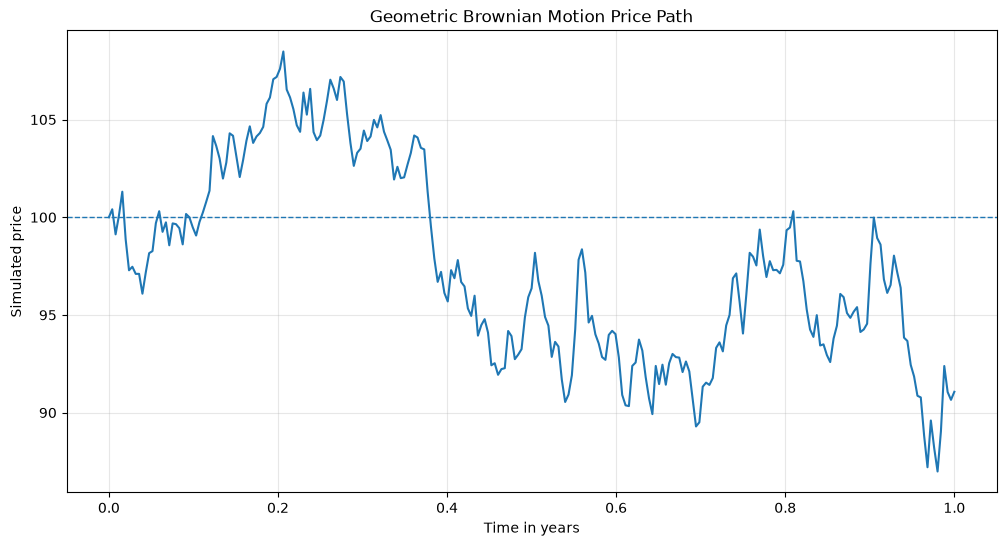

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    gbm_data["time"],
    gbm_data["price"],
    linewidth=1.5
)

ax.axhline(
    y=initial_price,
    linestyle="--",
    linewidth=1
)

ax.set_title("Geometric Brownian Motion Price Path")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.grid(alpha=0.3)

plt.show()

## 2.3 Log returns

The simulation is built in log space, so log returns are additive and exactly Gaussian. Simple returns $R_t = S_{t+\Delta t}/S_t - 1$ are related to them by $\ln(1 + R_t) = r_t$.

In [5]:
simple_returns = prices[1:] / prices[:-1] - 1

returns_data = pd.DataFrame({
    "simple_return": simple_returns,
    "log_return": log_returns
})

# The two definitions are linked exactly by log(1 + R) = r
maximum_difference = np.max(
    np.abs(log_returns - np.log1p(simple_returns))
)

print(f"Max |log return - log(1 + simple return)|: {maximum_difference:.2e}")
returns_data.head()

Max |log return - log(1 + simple return)|: 3.35e-16


,simple_return,log_return
0,0.004085,0.004077
1,-0.012782,-0.012864
2,0.009740,0.009693
3,0.012161,0.012088
4,-0.024049,-0.024343


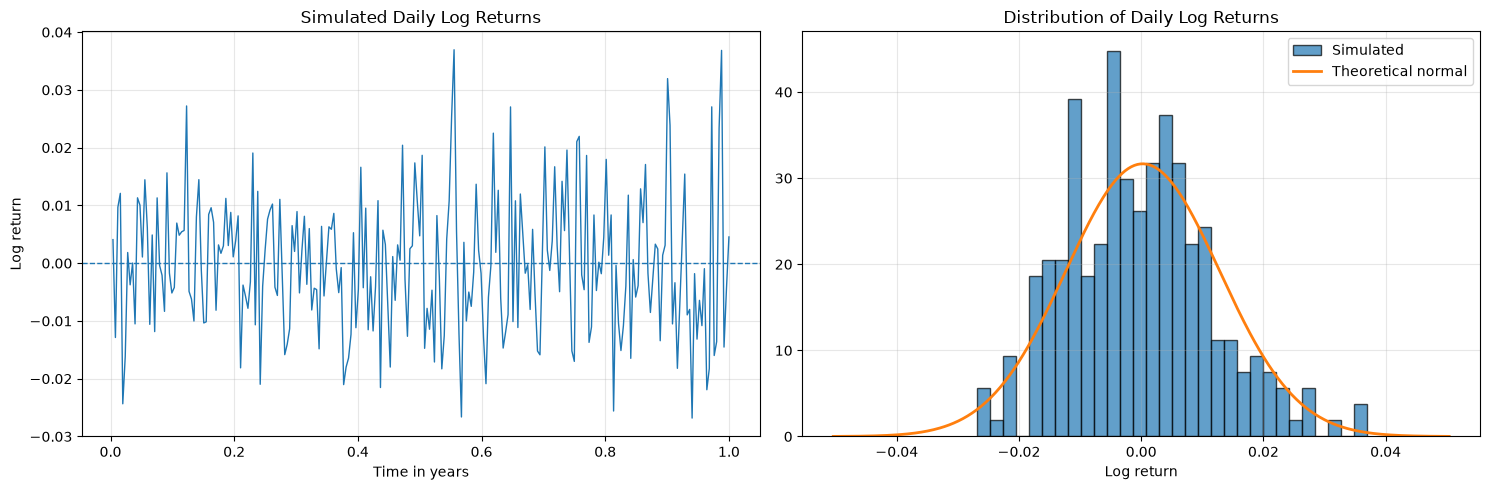

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(time[1:], log_returns, linewidth=1)
axes[0].axhline(y=0, linestyle="--", linewidth=1)
axes[0].set_title("Simulated Daily Log Returns")
axes[0].set_xlabel("Time in years")
axes[0].set_ylabel("Log return")

# Theoretical distribution of a single daily log return
log_return_mean = (annual_drift - 0.5 * annual_volatility**2) * dt
log_return_std = annual_volatility * np.sqrt(dt)
return_grid = np.linspace(-4 * log_return_std, 4 * log_return_std, 400)

axes[1].hist(log_returns, bins=30, density=True, alpha=0.7, edgecolor="black", label="Simulated")
axes[1].plot(
    return_grid,
    stats.norm.pdf(return_grid, log_return_mean, log_return_std),
    linewidth=2,
    label="Theoretical normal"
)
axes[1].set_title("Distribution of Daily Log Returns")
axes[1].set_xlabel("Log return")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
pd.Series({
    "initial_price": prices[0],
    "final_price": prices[-1],
    "minimum_price": prices.min(),
    "maximum_price": prices.max(),
    "total_simple_return": prices[-1] / prices[0] - 1,
    "total_log_return": np.log(prices[-1] / prices[0]),
    "mean_daily_log_return": log_returns.mean(),
    "theoretical_mean_daily_log_return": log_return_mean,
    "daily_log_return_std": log_returns.std(ddof=1),
    "theoretical_daily_log_return_std": log_return_std
})

initial_price                        100.000000
final_price                           91.067375
minimum_price                         86.987328
maximum_price                        108.484221
total_simple_return                   -0.089326
total_log_return                      -0.093571
mean_daily_log_return                 -0.000371
theoretical_mean_daily_log_return      0.000238
daily_log_return_std                   0.011813
theoretical_daily_log_return_std       0.012599
dtype: float64

A single path is one realisation. Over one day the drift term is about $\mu\,\Delta t \approx 0.03\%$, while the noise term is about $\sigma\sqrt{\Delta t} \approx 1.26\%$. Over short horizons the noise dominates, as with the drifted random walk in Notebook 1, because the deterministic part scales with $\Delta t$ and the stochastic part with $\sqrt{\Delta t}$.

## 2.4 Many paths and the terminal distribution

From here on the vectorised `simulate_gbm_paths` from the project package is used. It implements the same exact scheme as the cells above.

In [8]:
n_simulations = 10_000

time, all_prices = simulate_gbm_paths(
    initial_price=initial_price,
    drift=annual_drift,
    volatility=annual_volatility,
    time_horizon=time_horizon,
    n_steps=n_steps,
    n_paths=n_simulations,
    rng=rng
)

all_prices.shape

(10000, 253)

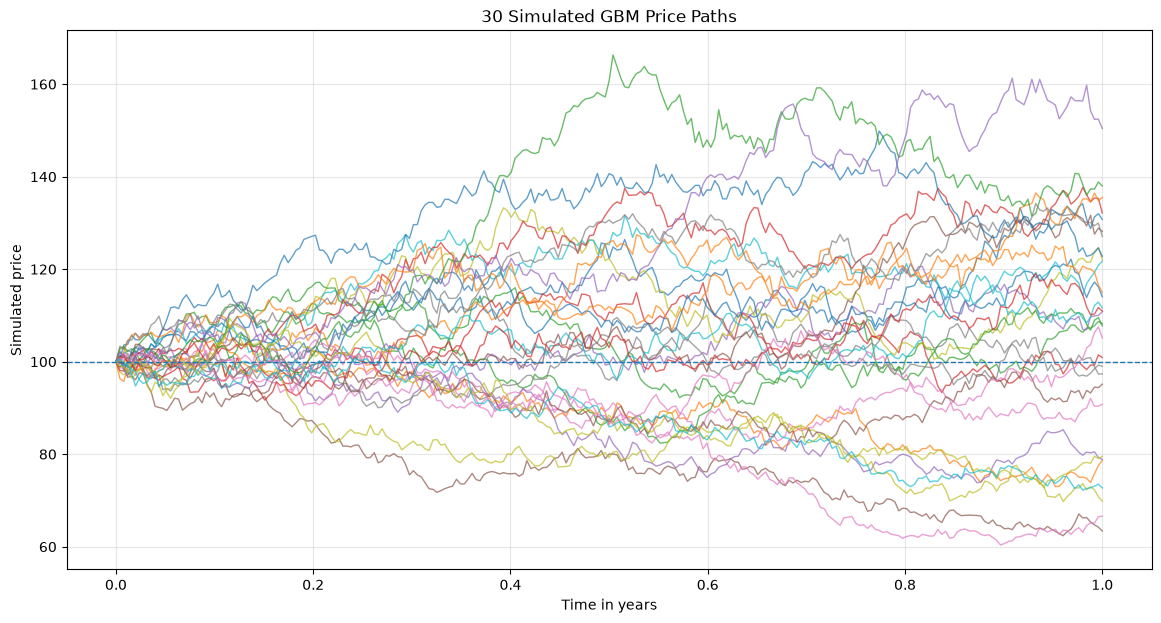

In [9]:
n_paths_to_plot = 30

fig, ax = plt.subplots(figsize=(14, 7))

for i in range(n_paths_to_plot):
    ax.plot(
        time,
        all_prices[i],
        linewidth=1,
        alpha=0.7
    )

ax.axhline(
    y=initial_price,
    linestyle="--",
    linewidth=1
)

ax.set_title(f"{n_paths_to_plot} Simulated GBM Price Paths")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.grid(alpha=0.3)

plt.show()

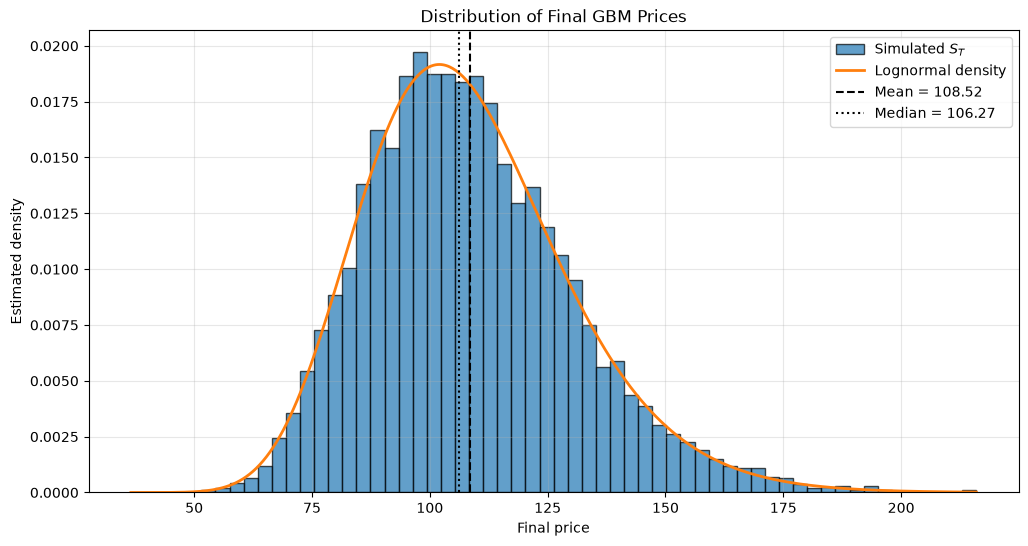

In [10]:
final_prices = all_prices[:, -1]

# Exact lognormal density of S_T: log S_T ~ N(log S0 + (mu - sigma^2/2) T, sigma^2 T)
lognormal_terminal = stats.lognorm(
    s=annual_volatility * np.sqrt(time_horizon),
    scale=gbm_median_price(initial_price, annual_drift, annual_volatility, time_horizon)
)
price_grid = np.linspace(final_prices.min(), final_prices.max(), 500)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    final_prices,
    bins=60,
    density=True,
    edgecolor="black",
    alpha=0.7,
    label="Simulated $S_T$"
)

ax.plot(price_grid, lognormal_terminal.pdf(price_grid), linewidth=2, label="Lognormal density")

ax.axvline(
    final_prices.mean(),
    linestyle="--",
    color="black",
    label=f"Mean = {final_prices.mean():.2f}"
)

ax.axvline(
    np.median(final_prices),
    linestyle=":",
    color="black",
    label=f"Median = {np.median(final_prices):.2f}"
)

ax.set_title("Distribution of Final GBM Prices")
ax.set_xlabel("Final price")
ax.set_ylabel("Estimated density")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

The terminal distribution is **lognormal**, not normal: it is right-skewed, bounded below by zero, and its mean lies above its median. Large upside moves are possible, but the price can never fall below zero.

In [11]:
mean_estimate = summarise_samples(final_prices)

theoretical_mean_final_price = gbm_expected_price(initial_price, annual_drift, time_horizon)
theoretical_median_final_price = gbm_median_price(
    initial_price, annual_drift, annual_volatility, time_horizon
)

pd.Series({
    "simulated_mean_final_price": mean_estimate.estimate,
    "theoretical_mean_final_price": theoretical_mean_final_price,
    "absolute_difference": abs(mean_estimate.estimate - theoretical_mean_final_price),
    "standard_error_of_mean": mean_estimate.standard_error,
    "difference_in_standard_errors": (
        abs(mean_estimate.estimate - theoretical_mean_final_price)
        / mean_estimate.standard_error
    ),
    "simulated_median_final_price": np.median(final_prices),
    "theoretical_median_final_price": theoretical_median_final_price
})

simulated_mean_final_price        108.523869
theoretical_mean_final_price      108.328707
absolute_difference                 0.195162
standard_error_of_mean              0.219985
difference_in_standard_errors       0.887161
simulated_median_final_price      106.273779
theoretical_median_final_price    106.183655
dtype: float64

The simulated mean does not match $S_0 e^{\mu T}$ exactly. This is **Monte Carlo sampling error**, not floating-point error: with $N$ paths, the sample mean has standard error $s/\sqrt{N}$, here about $0.2$. The observed gap is well within a couple of standard errors. Notebook 3 studies this error systematically.

In [12]:
probability_of_loss = np.mean(final_prices < initial_price)
theoretical_probability_of_loss = stats.norm.cdf(
    -(annual_drift - 0.5 * annual_volatility**2) * time_horizon
    / (annual_volatility * np.sqrt(time_horizon))
)

price_percentiles = np.percentile(final_prices, [5, 25, 50, 75, 95])

pd.Series({
    "probability_of_loss": probability_of_loss,
    "theoretical_probability_of_loss": theoretical_probability_of_loss,
    "5th percentile": price_percentiles[0],
    "25th percentile": price_percentiles[1],
    "median": price_percentiles[2],
    "75th percentile": price_percentiles[3],
    "95th percentile": price_percentiles[4]
})

probability_of_loss                  0.381600
theoretical_probability_of_loss      0.382089
5th percentile                      76.504729
25th percentile                     93.005948
median                             106.273779
75th percentile                    121.805560
95th percentile                    148.162711
dtype: float64

Even with an 8% drift, the model gives about a 38% chance of a loss over one year. Under GBM the probability of a loss shrinks as the horizon grows, because $(\mu - \sigma^2/2)T$ grows faster than $\sigma\sqrt{T}$. This assumes constant parameters and normal log returns, which real markets do not satisfy (fat tails, volatility clustering, jumps). GBM is a tractable baseline, not a realistic description.

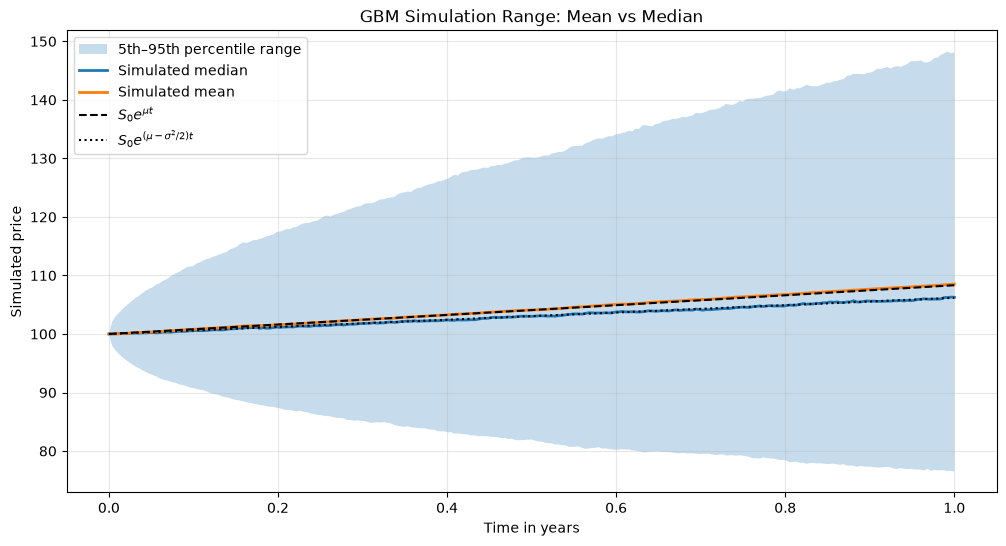

In [13]:
lower_band = np.percentile(all_prices, 5, axis=0)
median_path = np.percentile(all_prices, 50, axis=0)
upper_band = np.percentile(all_prices, 95, axis=0)

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(
    time,
    lower_band,
    upper_band,
    alpha=0.25,
    label="5th–95th percentile range"
)

ax.plot(time, median_path, linewidth=2, label="Simulated median")
ax.plot(time, all_prices.mean(axis=0), linewidth=2, label="Simulated mean")

ax.plot(
    time,
    gbm_expected_price(initial_price, annual_drift, time),
    linestyle="--",
    color="black",
    label=r"$S_0 e^{\mu t}$"
)

ax.plot(
    time,
    gbm_median_price(initial_price, annual_drift, annual_volatility, time),
    linestyle=":",
    color="black",
    label=r"$S_0 e^{(\mu - \sigma^2/2) t}$"
)

ax.set_title("GBM Simulation Range: Mean vs Median")
ax.set_xlabel("Time in years")
ax.set_ylabel("Simulated price")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [14]:
assert all_prices.shape == (n_simulations, n_steps + 1)
assert np.all(all_prices[:, 0] == initial_price)
assert np.all(all_prices > 0)
assert mean_estimate.contains(theoretical_mean_final_price)

print("GBM simulation checks passed.")

GBM simulation checks passed.


## 2.5 Effect of $\mu$, $\sigma$ and $T$

Each parameter is varied in turn while the others stay at their base values. Throughout, the analytical mean $S_0 e^{\mu T}$ and median $S_0 e^{(\mu-\sigma^2/2)T}$ are compared with simulation.

In [15]:
def simulate_parameter_case(drift, volatility, horizon, n_paths=10_000, steps_per_year=252):
    case_time, case_prices = simulate_gbm_paths(
        initial_price=initial_price,
        drift=drift,
        volatility=volatility,
        time_horizon=horizon,
        n_steps=int(steps_per_year * horizon),
        n_paths=n_paths,
        rng=rng
    )
    return case_time, case_prices


def plot_fan(ax, case_time, case_prices, label):
    median = np.percentile(case_prices, 50, axis=0)
    line, = ax.plot(case_time, median, linewidth=2, label=label)
    ax.fill_between(
        case_time,
        np.percentile(case_prices, 5, axis=0),
        np.percentile(case_prices, 95, axis=0),
        color=line.get_color(),
        alpha=0.15
    )

### Drift $\mu$

The drift shifts the whole distribution: it controls where prices go on average, but not how dispersed log returns are.

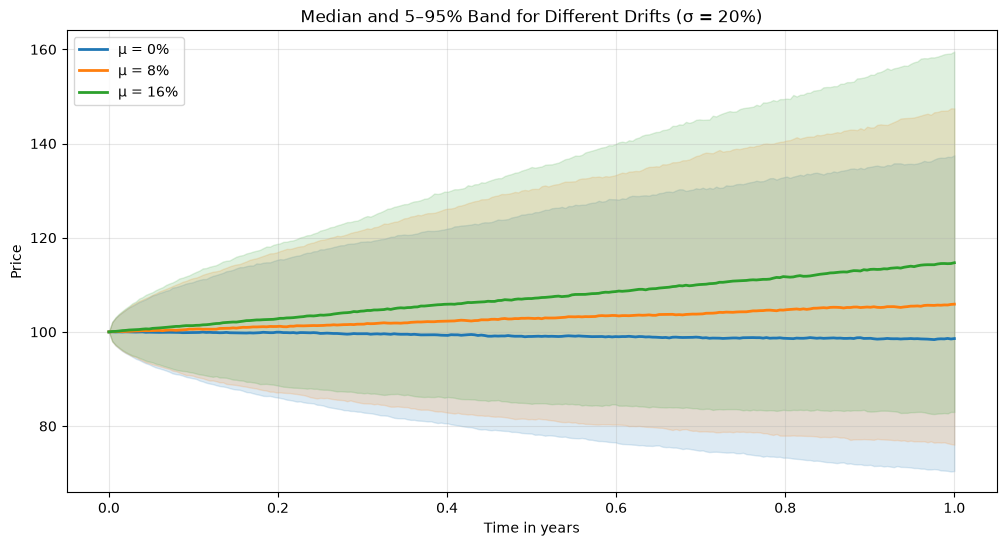

,simulated_mean,theoretical_mean,simulated_median,theoretical_median,std_of_log_return
mu,,,,,
0.00,100.428228,100.000000,98.579920,98.019867,0.202692
0.08,108.013059,108.328707,105.886958,106.183655,0.198795
0.16,117.063416,117.351087,114.683487,115.027380,0.199389


In [16]:
drift_values = [0.00, 0.08, 0.16]

fig, ax = plt.subplots(figsize=(12, 6))
drift_rows = []

for drift in drift_values:
    case_time, case_prices = simulate_parameter_case(drift, annual_volatility, 1)
    plot_fan(ax, case_time, case_prices, label=f"μ = {drift:.0%}")

    terminal = case_prices[:, -1]
    drift_rows.append({
        "mu": drift,
        "simulated_mean": terminal.mean(),
        "theoretical_mean": gbm_expected_price(initial_price, drift, 1),
        "simulated_median": np.median(terminal),
        "theoretical_median": gbm_median_price(initial_price, drift, annual_volatility, 1),
        "std_of_log_return": np.log(terminal / initial_price).std()
    })

ax.set_title("Median and 5–95% Band for Different Drifts (σ = 20%)")
ax.set_xlabel("Time in years")
ax.set_ylabel("Price")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame(drift_rows).set_index("mu")

### Volatility $\sigma$

Volatility widens the distribution and increases its skew. Because of the Itô correction, a higher $\sigma$ also **lowers the median** while leaving the mean unchanged. With high volatility most paths end below the mean, and a few large winners pull the mean up.

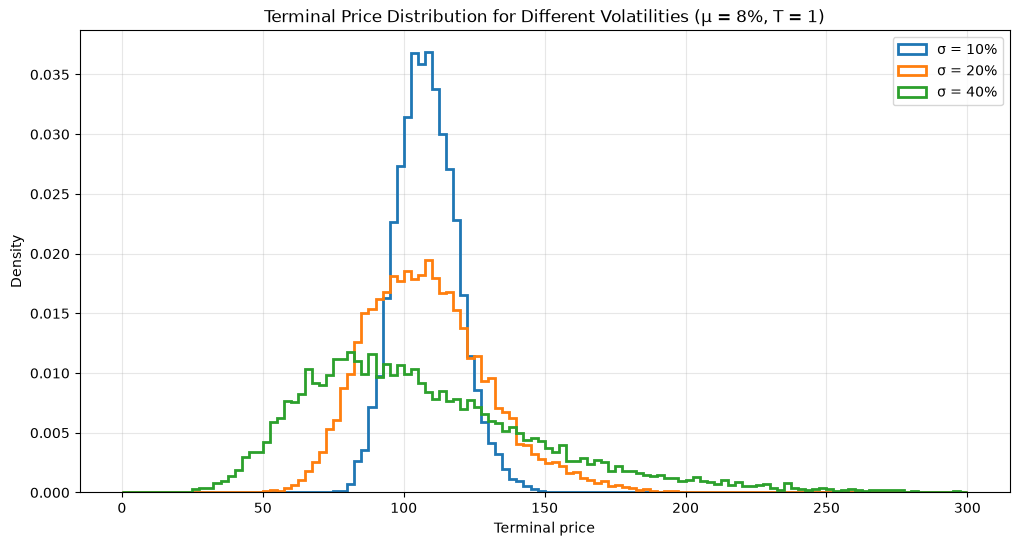

,simulated_mean,theoretical_mean,simulated_median,theoretical_median,probability_of_loss,skewness
sigma,,,,,,
0.1,108.378761,108.328707,107.873861,107.788415,0.2259,0.314084
0.2,108.368324,108.328707,106.599768,106.183655,0.3800,0.615782
0.4,107.936989,108.328707,99.642868,100.000000,0.5032,1.256404


In [17]:
volatility_values = [0.10, 0.20, 0.40]

fig, ax = plt.subplots(figsize=(12, 6))
volatility_rows = []

for volatility in volatility_values:
    _, case_prices = simulate_parameter_case(annual_drift, volatility, 1, steps_per_year=12)
    terminal = case_prices[:, -1]

    ax.hist(
        terminal,
        bins=np.linspace(0, 300, 121),
        density=True,
        histtype="step",
        linewidth=2,
        label=f"σ = {volatility:.0%}"
    )

    volatility_rows.append({
        "sigma": volatility,
        "simulated_mean": terminal.mean(),
        "theoretical_mean": gbm_expected_price(initial_price, annual_drift, 1),
        "simulated_median": np.median(terminal),
        "theoretical_median": gbm_median_price(initial_price, annual_drift, volatility, 1),
        "probability_of_loss": np.mean(terminal < initial_price),
        "skewness": stats.skew(terminal)
    })

ax.set_title("Terminal Price Distribution for Different Volatilities (μ = 8%, T = 1)")
ax.set_xlabel("Terminal price")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame(volatility_rows).set_index("sigma")

### Horizon $T$

The mean of $\ln(S_T/S_0)$ grows like $T$ and its standard deviation like $\sqrt{T}$, mirroring the drift-versus-noise trade-off of the random walk. The price bands fan out, and the gap between mean and median widens exponentially in $T$.

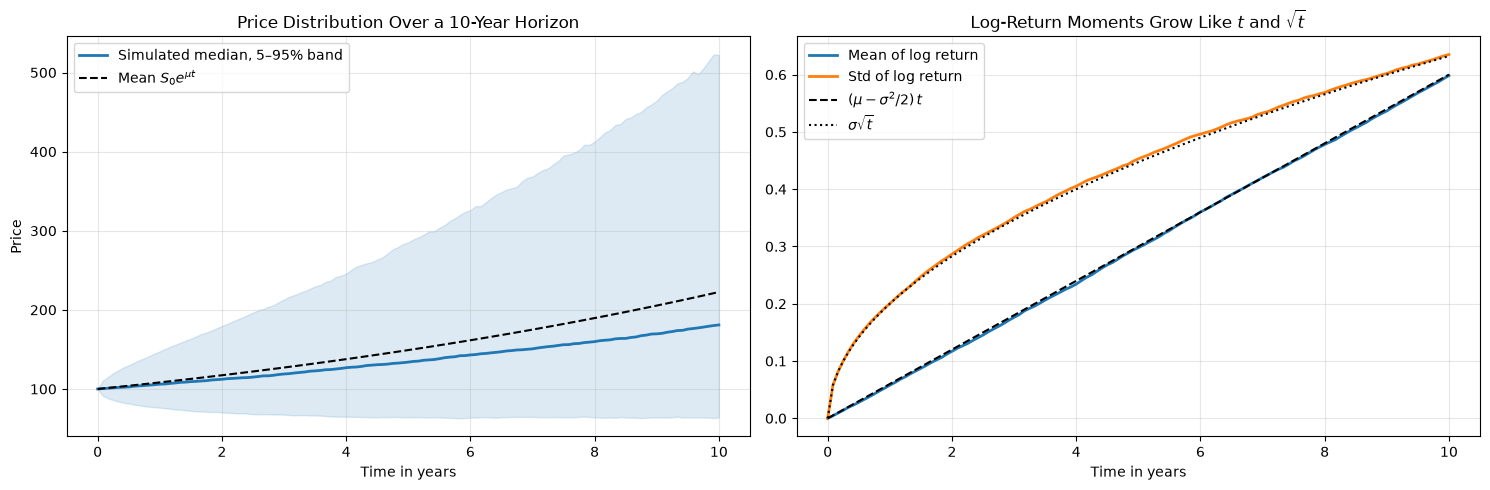

In [18]:
horizon = 10
case_time, case_prices = simulate_parameter_case(annual_drift, annual_volatility, horizon, steps_per_year=12)

log_growth = np.log(case_prices / initial_price)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_fan(axes[0], case_time, case_prices, label="Simulated median, 5–95% band")
axes[0].plot(case_time, gbm_expected_price(initial_price, annual_drift, case_time), "k--", label="Mean $S_0 e^{\\mu t}$")
axes[0].set_title("Price Distribution Over a 10-Year Horizon")
axes[0].set_xlabel("Time in years")
axes[0].set_ylabel("Price")

axes[1].plot(case_time, log_growth.mean(axis=0), linewidth=2, label="Mean of log return")
axes[1].plot(case_time, log_growth.std(axis=0), linewidth=2, label="Std of log return")
axes[1].plot(case_time, (annual_drift - 0.5 * annual_volatility**2) * case_time, "k--", label="$(\\mu - \\sigma^2/2)\\,t$")
axes[1].plot(case_time, annual_volatility * np.sqrt(case_time), "k:", label="$\\sigma\\sqrt{t}$")
axes[1].set_title("Log-Return Moments Grow Like $t$ and $\\sqrt{t}$")
axes[1].set_xlabel("Time in years")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusions

Geometric Brownian Motion turns the Brownian motion of Notebook 1 into a price model:

- solving $dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$ with Itô's lemma gives an explicit solution that can be simulated exactly;
- prices remain strictly positive;
- log returns are i.i.d. normal and terminal prices are lognormal;
- $\mu$ moves the distribution, $\sigma$ spreads and skews it, and $T$ scales the drift linearly and the noise like $\sqrt{T}$;
- the mean $S_0 e^{\mu T}$ and the median $S_0 e^{(\mu-\sigma^2/2)T}$ differ, and the gap grows with $\sigma$ and $T$.

The model assumes constant drift and volatility, independent returns and Gaussian log returns. Real markets show volatility clustering, heavy tails and jumps (see the separate empirical returns project).

Simulated averages differed slightly from their theoretical values because of sampling error. The next notebook makes that error the main subject: **Monte Carlo estimation**.